1.Load the data

In [3]:
import json
from huggingface_hub import hf_hub_download

FIELDS = ["document", "doc_bio_tags", "extractive_keyphrases", "abstractive_keyphrases"]

def load_split(filename):
    path = hf_hub_download("midas/inspec", filename, repo_type="dataset")
    with open(path, encoding="utf-8") as f:
        return [{field: json.loads(line)[field] for field in FIELDS} for line in f]

dataset = {
    "train": load_split("train.jsonl"),
    "validation": load_split("valid.jsonl"),
    "test": load_split("test.jsonl"),
}

for split, docs in dataset.items():
    print(f"{split}: {len(docs)} documents")

/Users/ficabogdan/keyword-extractor/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 1000 documents
validation: 500 documents
test: 500 documents


2.One example

In [4]:
sample = dataset["train"][0]

print(" ".join(sample["document"]))
print("\nPresent:", sample["extractive_keyphrases"])
print("Absent:", sample["abstractive_keyphrases"])

A conflict between language and atomistic information Fred Dretske and Jerry Fodor are responsible for popularizing three well-known theses in contemporary philosophy of mind : the thesis of Information-Based Semantics -LRB- IBS -RRB- , the thesis of Content Atomism -LRB- Atomism -RRB- and the thesis of the Language of Thought -LRB- LOT -RRB- . LOT concerns the semantically relevant structure of representations involved in cognitive states such as beliefs and desires . It maintains that all such representations must have syntactic structures mirroring the structure of their contents . IBS is a thesis about the nature of the relations that connect cognitive representations and their parts to their contents -LRB- semantic relations -RRB- . It holds that these relations supervene solely on relations of the kind that support information content , perhaps with some help from logical principles of combination . Atomism is a thesis about the nature of the content of simple symbols . It holds 

3.Statistics per split

In [5]:
import pandas as pd

rows = [
    {
        "split": split,
        "words": len(doc["document"]),
        "present": len(doc["extractive_keyphrases"]),
        "absent": len(doc["abstractive_keyphrases"]),
    }
    for split, docs in dataset.items()
    for doc in docs
]

stats = pd.DataFrame(rows)
stats.groupby("split").mean().round(2)

,words,present,absent
split,,,
test,134.60,6.57,3.26
train,141.51,6.39,3.39
validation,132.58,5.95,3.20


4.Share of present keyphrases


In [6]:
total_present = stats["present"].sum()
total_absent = stats["absent"].sum()
present_share = total_present / (total_present + total_absent)

print(f"Present: {total_present}, Absent: {total_absent}")
print(f"Present share: {present_share:.1%}")

Present: 12652, Absent: 6623
Present share: 65.6%


5.Keyphrases length

In [7]:
from collections import Counter

keyphrase_lengths = Counter(
    len(keyphrase.split())
    for doc in dataset["test"]
    for keyphrase in doc["extractive_keyphrases"]
)

total = sum(keyphrase_lengths.values())
for length, count in sorted(keyphrase_lengths.items()):
    print(f"{length} words: {count / total:.1%}")

1 words: 15.4%
2 words: 54.9%
3 words: 23.0%
4 words: 5.0%
5 words: 1.3%
6 words: 0.4%
7 words: 0.1%


6.Plots

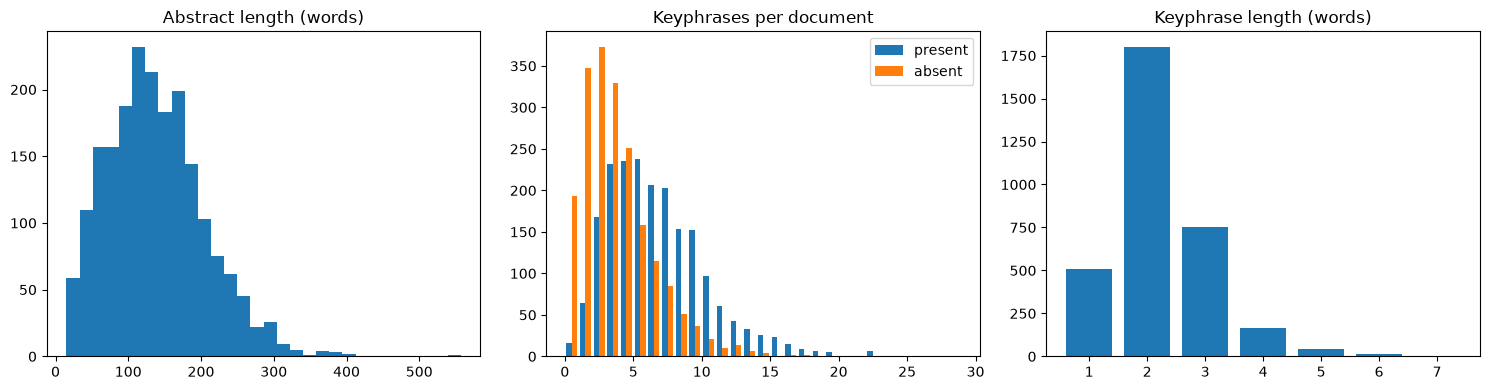

In [8]:
import matplotlib.pyplot as plt

lengths = sorted(keyphrase_lengths)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(stats["words"], bins=30)
axes[0].set_title("Abstract length (words)")

axes[1].hist([stats["present"], stats["absent"]], bins=range(0, 30), label=["present", "absent"])
axes[1].set_title("Keyphrases per document")
axes[1].legend()

axes[2].bar([str(n) for n in lengths], [keyphrase_lengths[n] for n in lengths])
axes[2].set_title("Keyphrase length (words)")

plt.tight_layout()
plt.savefig("results/01_data_stats.png", dpi=150)
plt.show()

7.Exact match check

In [9]:
pairs = [
    (keyphrase, " ".join(doc["document"]).lower())
    for doc in dataset["test"]
    for keyphrase in doc["extractive_keyphrases"]
]

found = sum(keyphrase in text for keyphrase, text in pairs)
print(f"{found}/{len(pairs)} present keyphrases appear verbatim ({found / len(pairs):.1%})")

3268/3283 present keyphrases appear verbatim (99.5%)
